# SomnIA: experimento 3, ¿agregar la boca ayuda a detectar la somnolencia?

Hasta ahora, el clasificador final solo recibía información de los **ojos**: $[z_L, z_R, \text{cierre}_L, \text{cierre}_R]$. Aquí se le agrega la **apertura de la boca** (bostezos), con dos fuentes distintas, y se mide si mejora el F1 y la sensibilidad de Drowsy en personas nunca vistas.

| Elemento | Experimento 3 |
|---|---|
| **Unidad experimental** | Clasificador final de somnolencia (por fotograma) |
| **Factor A: información de la boca** (3 niveles) | **Sin boca** (solo ojos) · **Boca geométrica**: MAR, la razón de apertura calculada con los puntos de MediaPipe, sin red · **Boca ViT**: apertura estimada por el ViT-B/16 entrenado con *jawOpen* (pliegue 0, r = 0,84 en prueba) |
| **Factor B: clasificador** (3) | Regresión logística · Michigan · Pittsburgh |
| **Factor C: red de ojos** (2) | Configuración del paper · la optimizada por **Luciérnagas** (la mejor del experimento 1) |
| **Entradas cuando hay boca** | Ojos + $[z_{boca}, \text{apertura}]$. $z_{boca}$ se calibra por persona igual que los ojos, con sus primeras 20 fotos alerta |
| **Respuestas** | **F1 de Drowsy** y **sensibilidad de Drowsy** en prueba (principales) y sensibilidad de alerta |
| **Variables controladas** | Misma partición por persona, mismas fotos de calibración y los mismos cierres de ojos del experimento 1 (caché de Colab) |
| **Repeticiones** | 3: cada una usa la red de ojos de esa semilla y la misma semilla para Michigan/Pittsburgh |
| **Casos** | 3 × 3 × 2 = 18 casos × 3 repeticiones = **54 ejecuciones**. No se reentrena ninguna red |
| **Análisis** | ANOVA de tres factores y t pareada (ojos + boca vs. solo ojos) |

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as smx
from statsmodels.formula.api import ols
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AQUI = Path.cwd()
sys.path.insert(0, str(AQUI)); import somnia_meta as sm
DRIVE = Path.home() / "Library/CloudStorage/GoogleDrive-lopezdanielh.566@gmail.com/Mi unidad/SomnIA_colab"
R = AQUI / "resultados"
meta = pd.read_csv(DRIVE / "meta_ojos.csv")
boca = pd.read_csv(AQUI / "boca_experimento.csv")            # mismo orden que meta_ojos.csv (predecir_boca.py)
assert len(boca) == len(meta) and (boca["person"].to_numpy() == meta["person"].to_numpy()).all()
D = sm.Datos(np.zeros((len(meta), 2, 1), np.float32), meta, paso_train=1)
E1 = pd.read_csv(R / "experimento1.csv")
print("Fotogramas:", {k: len(v) for k, v in D.idx.items()}, "| personas de prueba:", sorted(meta.loc[D.idx["test"], "person"].unique()))

Fotogramas: {'train': 4026, 'val': 9077, 'test': 7604} | personas de prueba: ['P05', 'P07', 'P15', 'P18', 'P20']


## 1. ¿Cuánta información trae la boca?
Antes del experimento conviene ver si la apertura de la boca cambia entre alerta y somnolencia, y en qué personas.

,Fuente,Partición,media alerta,media Drowsy,AUC Drowsy,"% bostezo en Drowsy (> 0,3)","% bostezo en alerta (> 0,3)"
0,Boca geométrica (MAR),train,0.015,0.020,0.450,0.825,0.000
1,Boca geométrica (MAR),test,0.013,0.023,0.513,0.481,0.026
2,Boca ViT,train,0.015,0.079,0.493,11.596,0.000
3,Boca ViT,test,0.030,0.015,0.421,0.080,0.026


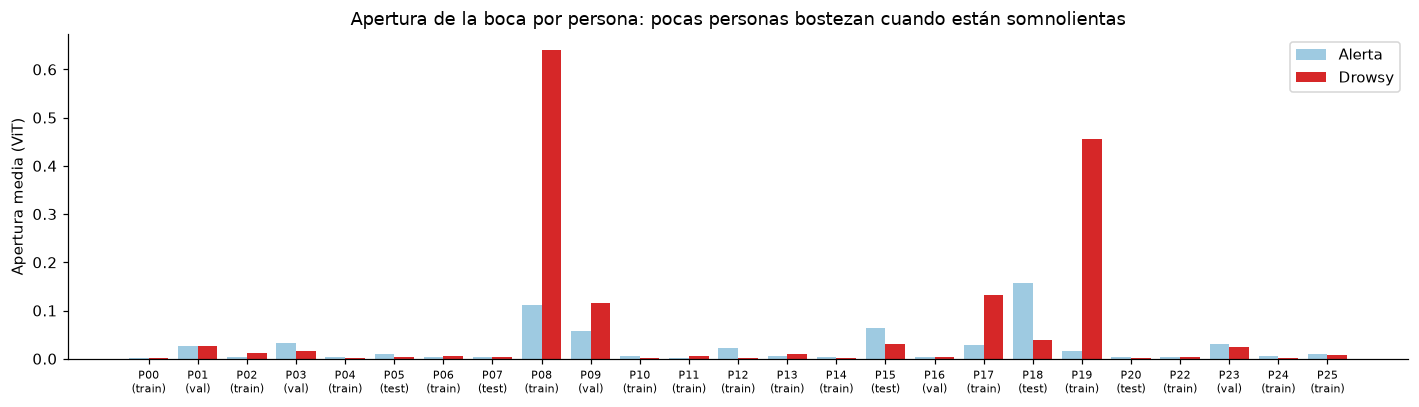

In [2]:
filas = []
for c, n in [("mar", "Boca geométrica (MAR)"), ("apertura_vit", "Boca ViT")]:
    for sp in ("train", "test"):
        b = boca[boca.split == sp]
        filas.append({"Fuente": n, "Partición": sp, "media alerta": b[b.label == 0][c].mean(), "media Drowsy": b[b.label == 1][c].mean(),
                      "AUC Drowsy": roc_auc_score(b.label, b[c]), "% bostezo en Drowsy (> 0,3)": (b[b.label == 1][c] > 0.3).mean() * 100,
                      "% bostezo en alerta (> 0,3)": (b[b.label == 0][c] > 0.3).mean() * 100})
display(pd.DataFrame(filas).round(3))
piv = boca.groupby(["person", "label"])["apertura_vit"].mean().unstack().rename(columns={0: "alerta", 1: "Drowsy"})
piv["partición"] = boca.groupby("person")["split"].first()
fig, ax = plt.subplots(figsize=(13, 3.8))
x = np.arange(len(piv)); ax.bar(x - 0.2, piv["alerta"], 0.4, label="Alerta", color="#9ecae1"); ax.bar(x + 0.2, piv["Drowsy"], 0.4, label="Drowsy", color="#d62728")
ax.set_xticks(x, [f"{p}\n({s})" for p, s in zip(piv.index, piv["partición"])], fontsize=7)
ax.set(ylabel="Apertura media (ViT)", title="Apertura de la boca por persona: pocas personas bostezan cuando están somnolientas"); ax.legend()
plt.tight_layout(); plt.savefig(R / "fig_boca_por_persona.png", dpi=150); plt.show()

## 2. Ejecución del experimento (54 ejecuciones)

In [3]:
def caracteristicas(clave, fuente):
    z = np.load(DRIVE / "cache" / f"{clave}.npz"); out = {}
    for p in ("train", "test"):
        Fo, ok = sm.calibrar(D, D.idx[p], z[p])
        X, nombres = Fo, ["z_L", "z_R", "closure_L", "closure_R"]
        if fuente != "Sin boca":
            col = "mar" if fuente.startswith("Boca geom") else "apertura_vit"
            a_all = np.full((len(meta), 2), np.nan, np.float32); a_all[:, 0] = a_all[:, 1] = boca[col].to_numpy()
            Fb, okb = sm.calibrar(D, D.idx[p], a_all[D.idx[p]])            # z de la boca con las mismas fotos de referencia
            X = np.concatenate([Fo, Fb[:, [0, 2]]], 1); ok = ok & okb; nombres = nombres + ["z_boca", "boca"]
        out[p] = (X[ok], D.label[D.idx[p]][ok])
    return out, nombres

FUENTES = ["Sin boca", "Boca geométrica (MAR)", "Boca ViT"]
REDES = {"Paper": "Paper (sin búsqueda)", "Luciérnagas": "Luciérnagas"}
filas, REGLAS, COEF = [], {}, {}
for rep in range(3):
    for red, alg in REDES.items():
        clave = E1[(E1.algoritmo == alg) & (E1.repeticion == rep)]["clave"].iloc[0]
        for fuente in FUENTES:
            X, nombres = caracteristicas(clave, fuente); (Xtr, ytr), (Xte, yte) = X["train"], X["test"]
            for nombre in ["Regresión logística", "Michigan", "Pittsburgh"]:
                if nombre == "Regresión logística":
                    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(Xtr, ytr)
                    if rep == 0: COEF[(red, fuente)] = dict(zip(nombres, clf[-1].coef_[0].round(3)))
                else:
                    clf = (sm.Michigan if nombre == "Michigan" else sm.Pittsburgh)(rng=np.random.default_rng(rep)).fit(Xtr, ytr, nombres=nombres)
                    if rep == 0: REGLAS[(nombre, red, fuente)] = clf.reglas()
                p = clf.predict(Xte)
                usa_boca = np.nan
                if nombre == "Pittsburgh" and fuente != "Sin boca":
                    usa_boca = int(any(("boca" in r) for r in clf.reglas()))
                filas.append({"boca": fuente, "clasificador": nombre, "red": red, "repeticion": rep, **sm.metricas(yte, p), "reglas_usan_boca": usa_boca})
    print("repetición", rep, "lista", flush=True)
E3 = pd.DataFrame(filas); E3.to_csv(R / "experimento3_boca.csv", index=False)
print(len(E3), "ejecuciones")

repetición 0 lista


repetición 1 lista


repetición 2 lista


54 ejecuciones


## 3. Resultados: F1 y sensibilidad de Drowsy en prueba

In [4]:
ms = lambda g, c: (g[c].mean() * 100).round(1).astype(str) + " ± " + (g[c].std() * 100).round(1).astype(str)
g = E3.groupby(["red", "clasificador", "boca"], sort=False)
T3 = pd.DataFrame({"F1 Drowsy (%)": ms(g, "f1"), "Sens. Drowsy (%)": ms(g, "recall_drowsy"), "Sens. alerta (%)": ms(g, "recall_alerta")})
T3.to_csv(R / "tabla_experimento3_boca.csv"); T3

F1 Drowsy (%)  \
red         clasificador        boca                                  
Paper       Regresión logística Sin boca                 72.8 ± 0.6   
            Michigan            Sin boca                 72.8 ± 6.2   
            Pittsburgh          Sin boca                 73.7 ± 0.3   
            Regresión logística Boca geométrica (MAR)    73.7 ± 0.6   
            Michigan            Boca geométrica (MAR)    71.7 ± 3.4   
            Pittsburgh          Boca geométrica (MAR)    71.2 ± 0.5   
            Regresión logística Boca ViT                 71.8 ± 1.0   
            Michigan            Boca ViT                 66.1 ± 7.0   
            Pittsburgh          Boca ViT                 74.1 ± 2.7   
Luciérnagas Regresión logística Sin boca                 76.3 ± 0.6   
            Michigan            Sin boca                 74.1 ± 3.8   
            Pittsburgh          Sin boca                 73.4 ± 1.7   
            Regresión logística Boca geométrica (MAR)    76.5 ± 1.2   
            Michigan            Boca geométrica (MAR)    72.9 ± 3.3   
            Pittsburgh          Boca geométrica (MAR)    74.1 ± 3.2   
            Regresión logística Boca ViT                 67.3 ± 3.6   
            Michigan            Boca ViT                 74.6 ± 3.9   
            Pittsburgh          Boca ViT                 75.6 ± 0.9   

                                                      Sens. Drowsy (%)  \
red         clasificador        boca                                     
Paper       Regresión logística Sin boca                    80.8 ± 0.7   
            Michigan            Sin boca                    79.7 ± 1.6   
            Pittsburgh          Sin boca                    83.0 ± 1.0   
            Regresión logística Boca geométrica (MAR)       81.7 ± 0.7   
            Michigan            Boca geométrica (MAR)       86.3 ± 6.0   
            Pittsburgh          Boca geométrica (MAR)       82.3 ± 2.2   
            Regresión logística Boca ViT                    71.5 ± 1.4   
            Michigan            Boca ViT                   73.6 ± 10.3   
            Pittsburgh          Boca ViT                    81.8 ± 1.6   
Luciérnagas Regresión logística Sin boca                    85.2 ± 1.9   
            Michigan            Sin boca                    83.6 ± 9.3   
            Pittsburgh          Sin boca                    85.1 ± 1.6   
            Regresión logística Boca geométrica (MAR)       85.3 ± 1.6   
            Michigan            Boca geométrica (MAR)       87.6 ± 3.9   
            Pittsburgh          Boca geométrica (MAR)       86.8 ± 5.3   
            Regresión logística Boca ViT                    62.2 ± 2.6   
            Michigan            Boca ViT                    82.2 ± 7.3   
            Pittsburgh          Boca ViT                    83.6 ± 2.1   

                                                      Sens. alerta (%)  
red         clasificador        boca                                    
Paper       Regresión logística Sin boca                    58.9 ± 2.0  
            Michigan            Sin boca                   59.4 ± 19.8  
            Pittsburgh          Sin boca                    57.6 ± 2.3  
            Regresión logística Boca geométrica (MAR)       59.8 ± 1.6  
            Michigan            Boca geométrica (MAR)       45.6 ± 3.4  
            Pittsburgh          Boca geométrica (MAR)       50.9 ± 2.4  
            Regresión logística Boca ViT                    72.1 ± 1.1  
            Michigan            Boca ViT                   51.3 ± 11.2  
            Pittsburgh          Boca ViT                   60.8 ± 10.4  
Luciérnagas Regresión logística Sin boca                    61.6 ± 2.6  
            Michigan            Sin boca                   58.0 ± 10.6  
            Pittsburgh          Sin boca                    53.2 ± 3.4  
            Regresión logística Boca geométrica (MAR)       62.2 ± 4.1  
            Michigan            Boca geométrica (MAR)    

Efecto principal de la boca (promedio sobre clasificadores, redes y repeticiones):


,f1,recall_drowsy,recall_alerta
boca,,,
Sin boca,73.8,82.9,58.1
Boca geométrica (MAR),73.4,85.0,53.1
Boca ViT,71.6,75.8,64.3


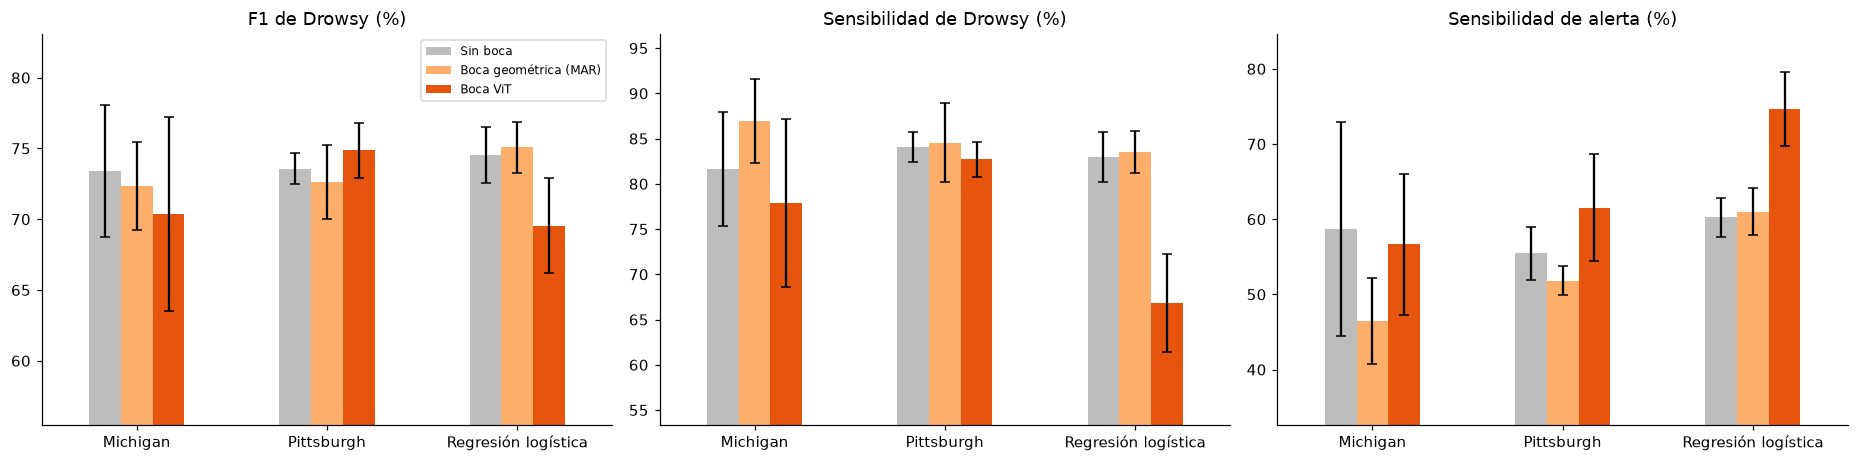

In [5]:
print("Efecto principal de la boca (promedio sobre clasificadores, redes y repeticiones):")
display((E3.groupby("boca")[["f1", "recall_drowsy", "recall_alerta"]].mean() * 100).reindex(FUENTES).round(1))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for k, (m, tit) in enumerate([("f1", "F1 de Drowsy (%)"), ("recall_drowsy", "Sensibilidad de Drowsy (%)"), ("recall_alerta", "Sensibilidad de alerta (%)")]):
    piv = E3.groupby(["clasificador", "boca"])[m].mean().unstack()[FUENTES] * 100
    err = E3.groupby(["clasificador", "boca"])[m].std().unstack()[FUENTES] * 100
    piv.plot.bar(yerr=err, ax=ax[k], rot=0, capsize=3, color=["#bdbdbd", "#fdae6b", "#e6550d"], legend=(k == 0))
    ax[k].set(title=tit, xlabel="", ylim=(max(0, (piv - err).values.min() - 8), min(100, (piv + err).values.max() + 5)))
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(R / "fig_experimento3_boca.png", dpi=150); plt.show()

### 3.1 ANOVA de tres factores

$Y = \mu + \alpha_{boca} + \beta_{clasificador} + \gamma_{red} + (\alpha\beta) + (\alpha\gamma) + (\beta\gamma) + \varepsilon$

$H_0$ para el factor boca: agregar la boca no cambia la métrica.

In [6]:
for r, n in [("f1", "F1 de Drowsy"), ("recall_drowsy", "Sensibilidad de Drowsy")]:
    A = smx.stats.anova_lm(ols(f"{r} ~ C(boca) + C(clasificador) + C(red) + C(boca):C(clasificador) + C(boca):C(red) + C(clasificador):C(red)", data=E3).fit(), typ=2)
    print(f"\n=== ANOVA: {n} ===")
    display(A.round(4))
    print("  ->", "la BOCA influye (p < 0,05)" if A.loc["C(boca)", "PR(>F)"] < 0.05 else f"la boca NO cambia {n} de forma significativa (p = {A.loc['C(boca)', 'PR(>F)']:.3f})")


=== ANOVA: F1 de Drowsy ===


,sum_sq,df,F,PR(>F)
C(boca),0.0050,2.0,2.1375,0.1312
C(clasificador),0.0025,2.0,1.0666,0.3538
C(red),0.0048,1.0,4.0704,0.0504
C(boca):C(clasificador),0.0105,4.0,2.2310,0.0828
C(boca):C(red),0.0002,2.0,0.0729,0.9298
C(clasificador):C(red),0.0023,2.0,0.9564,0.3929
Residual,0.0472,40.0,NaN,NaN


  -> la boca NO cambia F1 de Drowsy de forma significativa (p = 0.131)

=== ANOVA: Sensibilidad de Drowsy ===


,sum_sq,df,F,PR(>F)
C(boca),0.0835,2.0,18.1477,0.0000
C(clasificador),0.0344,2.0,7.4719,0.0017
C(red),0.0072,1.0,3.1344,0.0843
C(boca):C(clasificador),0.0503,4.0,5.4585,0.0013
C(boca):C(red),0.0026,2.0,0.5725,0.5687
C(clasificador):C(red),0.0058,2.0,1.2504,0.2973
Residual,0.0921,40.0,NaN,NaN


  -> la BOCA influye (p < 0,05)


### 3.2 Prueba t pareada: ojos + boca vs. solo ojos (mismo clasificador, misma red, misma repetición)

In [7]:
filas = []
base = E3[E3.boca == "Sin boca"].set_index(["clasificador", "red", "repeticion"])
for fuente in FUENTES[1:]:
    otro = E3[E3.boca == fuente].set_index(["clasificador", "red", "repeticion"]).loc[base.index]
    for r, n in [("f1", "F1 Drowsy"), ("recall_drowsy", "Sens. Drowsy"), ("recall_alerta", "Sens. alerta")]:
        d = otro[r].values - base[r].values; t, p = stats.ttest_rel(otro[r].values, base[r].values)
        filas.append({"Comparación": f"{fuente} vs. sin boca", "Métrica": n, "n pares": len(d), "diferencia media (pts)": round(d.mean() * 100, 2),
                      "pares en que mejora": f"{(d > 0).sum()} de {len(d)}", "t": round(t, 3), "p (dos colas)": round(p, 4),
                      "¿Significativo?": "Sí" if p < 0.05 else "No"})
TP3 = pd.DataFrame(filas).set_index(["Comparación", "Métrica"]); TP3.to_csv(R / "t_pareada_boca.csv"); TP3

n pares  \
Comparación                        Métrica                 
Boca geométrica (MAR) vs. sin boca F1 Drowsy          18   
                                   Sens. Drowsy       18   
                                   Sens. alerta       18   
Boca ViT vs. sin boca              F1 Drowsy          18   
                                   Sens. Drowsy       18   
                                   Sens. alerta       18   

                                                 diferencia media (pts)  \
Comparación                        Métrica                                
Boca geométrica (MAR) vs. sin boca F1 Drowsy                      -0.48   
                                   Sens. Drowsy                    2.11   
                                   Sens. alerta                   -5.06   
Boca ViT vs. sin boca              F1 Drowsy                      -2.25   
                                   Sens. Drowsy                   -7.09   
                                   Sens. alerta                    6.18   

                                                pares en que mejora      t  \
Comparación                        Métrica                                   
Boca geométrica (MAR) vs. sin boca F1 Drowsy               10 de 18 -0.667   
                                   Sens. Drowsy            13 de 18  1.805   
                                   Sens. alerta             7 de 18 -2.498   
Boca ViT vs. sin boca              F1 Drowsy                7 de 18 -1.381   
                                   Sens. Drowsy             5 de 18 -3.061   
                                   Sens. alerta            13 de 18  2.046   

                                                 p (dos colas) ¿Significativo?  
Comparación                        Métrica                                      
Boca geométrica (MAR) vs. sin boca F1 Drowsy            0.5134              No  
                                   Sens. Drowsy         0.0887              No  
                                   Sens. alerta         0.0231              Sí  
Boca ViT vs. sin boca              F1 Drowsy            0.1851              No  
                                   Sens. Drowsy         0.0071              Sí  
                                   Sens. alerta         0.0566              No

### 3.3 ¿Qué hacen los clasificadores con la boca?

In [8]:
print("Coeficientes de la regresión logística (repetición 0, variables estandarizadas). Un coeficiente positivo empuja hacia Drowsy:")
display(pd.DataFrame(COEF).T)
for (nombre, red, fuente), reglas in REGLAS.items():
    if fuente == "Sin boca" or red != "Luciérnagas": continue
    print(f"\n--- {nombre} | red {red} | {fuente} ---")
    for r in reglas[:8]:
        print("  ", r if isinstance(r, str) else f"{r[0]}   (precisión {r[1]:.2f}, usada {r[2]} veces)")

Coeficientes de la regresión logística (repetición 0, variables estandarizadas). Un coeficiente positivo empuja hacia Drowsy:


z_L    z_R  closure_L  closure_R  z_boca  \
Paper       Sin boca              -0.088  1.788     -0.801      1.633     NaN   
            Boca geométrica (MAR) -0.248  1.935     -0.582      1.408   0.086   
            Boca ViT              -0.657  2.353      0.247      0.736   3.613   
Luciérnagas Sin boca               0.304  1.573     -0.172      1.027     NaN   
            Boca geométrica (MAR)  0.136  1.748      0.002      0.821   0.164   
            Boca ViT               0.024  1.891      0.872      0.089   3.650   

                                    boca  
Paper       Sin boca                 NaN  
            Boca geométrica (MAR)  0.175  
            Boca ViT              -0.764  
Luciérnagas Sin boca                 NaN  
            Boca geométrica (MAR)  0.113  
            Boca ViT              -0.885


--- Michigan | red Luciérnagas | Boca geométrica (MAR) ---
   SI z_R ∈ [11.60, 17.58] Y z_boca ∈ [-4.44, 0.87] Y boca ∈ [0.00, 0.01] → Drowsy   (precisión 1.00, usada 197 veces)
   SI z_R ∈ [11.60, 17.58] Y z_boca ∈ [-4.44, 0.87] Y boca ∈ [0.00, 0.01] → Drowsy   (precisión 1.00, usada 196 veces)
   SI z_R ∈ [11.60, 17.58] Y z_boca ∈ [-4.44, 0.87] Y boca ∈ [0.00, 0.01] → Drowsy   (precisión 1.00, usada 195 veces)
   SI z_L ∈ [2.70, 5.37] Y z_R ∈ [2.36, 6.88] Y closure_L ∈ [0.67, 0.76] Y closure_R ∈ [0.69, 0.75] Y z_boca ∈ [-0.84, 2.39] Y boca ∈ [-0.02, 0.02] → Drowsy   (precisión 0.99, usada 255 veces)
   SI z_L ∈ [-0.17, 4.94] Y closure_L ∈ [0.67, 0.76] Y boca ∈ [0.00, 0.03] → Drowsy   (precisión 0.97, usada 288 veces)
   SI z_L ∈ [-0.17, 4.94] Y z_R ∈ [-9.81, 12.26] Y closure_L ∈ [0.67, 0.76] Y boca ∈ [0.00, 0.03] → Drowsy   (precisión 0.97, usada 285 veces)
   SI z_L ∈ [-0.86, 5.57] Y z_R ∈ [2.31, 5.42] Y closure_L ∈ [0.18, 0.33] Y z_boca ∈ [-3.38, 3.18] Y boca ∈ [-0.00, 0.02] → Dro

## 4. Conclusiones

**Resultado principal: agregar la boca no mejora el F1 de Drowsy.** El ANOVA de tres factores da p = 0,13 para el factor boca, sin diferencia significativa. Lo que sí hace la boca es **mover el compromiso entre detectar somnolencia y evitar falsas alarmas**: el factor boca es significativo para la sensibilidad de Drowsy (p < 0,001) y para la de alerta (p < 0,001).

| Información de la boca | F1 Drowsy | Sens. Drowsy | Sens. alerta |
|---|---|---|---|
| Sin boca (solo ojos) | 73,8 % | 82,9 % | 58,1 % |
| Boca geométrica (MAR) | 73,4 % | **85,0 %** | 53,1 % |
| Boca ViT | 71,6 % | 75,8 % | **64,3 %** |

- **Boca ViT vs. solo ojos (t pareada, 18 pares):**
  - la sensibilidad de Drowsy **baja 7,1 puntos** (p = 0,007, significativo);
  - la sensibilidad de alerta sube 6,2 puntos (p = 0,057).
  - El clasificador usa la boca sobre todo para decir *"alerta"*: el modelo genera menos falsas alarmas, pero deja pasar más conductores somnolientos. Con la regresión logística el efecto es fuerte; por ejemplo, con la red de Luciérnagas la sensibilidad de Drowsy cae de 85,2 % a 62,2 %.
- **Boca geométrica (MAR) vs. solo ojos:**
  - la sensibilidad de Drowsy sube 2,1 puntos (p = 0,09, no significativo);
  - la de alerta baja 5,1 puntos (p = 0,02).
  - Agrega casi pura variación: su correlación con *jawOpen* es de solo 0,10.
- **Pittsburgh es el único clasificador que mejora un poco con la boca ViT.** Su F1 sube de 73,7 a 74,1 % con la red del paper y de 73,4 a 75,6 % con la de Luciérnagas, y sus reglas sí incluyen la boca. Aun así, la interacción boca × clasificador no es significativa para el F1 (p = 0,08).
- **El motivo está en los datos, no en el modelo de la boca.**
  - El ViT funciona bien: correlación de 0,84 con *jawOpen* y AUC de 0,97 para detectar bostezos.
  - Pero en el DDD **casi nadie bosteza**: solo 4 de las 25 personas (P08, P19, P17 y P09) abren claramente la boca cuando están somnolientas.
  - **Ninguna de las 5 personas de prueba bosteza**, y P18 abre más la boca estando alerta.
  - Por eso, lo que el clasificador aprende de la boca en entrenamiento no se repite en prueba.
- **Implicación para SomnIA:** los **ojos** son la señal principal de la somnolencia por fotograma. La boca sirve como detector complementario de **bostezos**, pero conviene evaluarla en **secuencias de video** (un bostezo dura varios segundos) y en datos donde las personas realmente bostecen. Agregarla como una variable más del clasificador por fotograma no ayuda.